# Этап 7. Время эпизода и реальный объем прогонов

Код: `rssrl/volume.py`. Проверки: `tests/test_volume.py`.

Вопросы этапа:
1. Сколько считается один эпизод на одном ядре и при параллельном счете?
2. Куда уходит время — в наш код или в highway-env?
3. Сколько сцен нужно на уровень β, чтобы классифицировать исходы (хуже / лучше / эквивалентно / неопределенно) с поправкой Холма?
4. Сколько займут оценка и обучение PPO на этом компьютере?

Числа ниже зависят от компьютера и его загрузки: это порядок величин, а не константы.

In [1]:
import sys
sys.path.insert(0, '..')
import os, time, cProfile, pstats
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rssrl.pilot import run_grid
from rssrl.scenarios import make_scene, run_episode
from rssrl.volume import (time_episodes, discordance, episodes_needed,
                          min_detectable, holm_z, evaluation_plan)

FIG = Path('..') / 'results' / 'figures'
PILOT = Path('..') / 'results' / 'pilot_07'  # таблицы пилота, в git не идут
PILOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
print('ядер (логических):', os.cpu_count(), '| загрузка (1 мин):', round(os.getloadavg()[0], 1))

ядер (логических): 8 | загрузка (1 мин): 3.8


## 1. Время эпизода на одном ядре

In [2]:
setups = [
    ('nominal', (1.0, False, 0.0), 'номинальный, без фильтра'),
    ('nominal', (1.0, True, 0.0), 'номинальный, фильтр'),
    ('brake', (2.0, True, 0.5), 'тормозящий β = 2, фильтр, задержка ρ'),
]
frames = []
for kind, (level, shield, delay), label in setups:
    t = time_episodes([(s, level, shield, delay) for s in range(8)], kind)
    t['вариант'] = label
    frames.append(t)
single = pd.concat(frames)
single['с счета на 1 с симуляции'] = single.wall_s / single.sim_s
single.groupby('вариант', sort=False).agg(
    эпизодов=('wall_s', 'size'),
    счет_с=('wall_s', 'mean'),
    симуляция_с=('sim_s', 'mean'),
    счет_на_1с_симуляции=('с счета на 1 с симуляции', 'mean'),
).round(3)

,эпизодов,счет_с,симуляция_с,счет_на_1с_симуляции
вариант,,,,
"номинальный, без фильтра",8,2.207,21.250,0.104
"номинальный, фильтр",8,4.137,40.000,0.103
"тормозящий β = 2, фильтр, задержка ρ",8,1.358,13.125,0.104


Время пропорционально длине эпизода в секундах симуляции: эпизод без фильтра короче, потому что заканчивается столкновением. Полный эпизод 40 с — около 4 с счета на одном ядре.

## 2. Куда уходит время

In [3]:
pr = cProfile.Profile()
pr.enable()
run_episode(make_scene(5, shield=True, kind='nominal'))
pr.disable()
st = pstats.Stats(pr)
total = sum(v[2] for v in st.stats.values())  # собственное время всех функций
def group(path):
    if 'rssrl' in path: return 'наш код (rssrl: фильтр, нарушители, логгер)'
    if 'highway_env' in path: return 'highway-env (фон, столкновения, дорога)'
    if 'numpy' in path: return 'numpy (вызывается из highway-env и нашего кода)'
    return 'прочее (Python, gymnasium)'
share = {}
for (path, _, _), v in st.stats.items():
    share[group(path)] = share.get(group(path), 0) + v[2]
(pd.Series(share) / total).sort_values(ascending=False).round(3).to_frame('доля времени')

,доля времени
"highway-env (фон, столкновения, дорога)",0.660
numpy (вызывается из highway-env и нашего кода),0.165
"прочее (Python, gymnasium)",0.164
"наш код (rssrl: фильтр, нарушители, логгер)",0.011


Основное время уходит на сам highway-env: каждая из 50 фоновых машин на каждом из 600 шагов ищет соседей (IDM, MOBIL) и проверяет столкновения со всеми. Наш фильтр, нарушители и логгер — малая доля. Поэтому ускорять наш код бессмысленно, а уменьшать число машин или частоту симуляции нельзя: это изменит сам эксперимент.

## 3. Параллельный счет и пилот по сетке β

Основной эксперимент в миниатюре: 50 сцен × 6 уровней β × 3 варианта (без фильтра, фильтр с задержкой 0 и ρ), агент IDLE вместо PPO. Это одновременно замер скорости параллельного счета и источник оценки разброса для расчета объема.

In [4]:
BETAS = [1.0, 1.2, 1.4, 1.6, 1.8, 2.0]
VARIANTS = [(False, 0.0), (True, 0.0), (True, 0.5)]
NAMES = {(False, 0.0): 'без фильтра', (True, 0.0): 'фильтр, задержка 0',
         (True, 0.5): 'фильтр, задержка ρ'}
t0 = time.perf_counter()
grid, _ = run_grid(range(50), BETAS, VARIANTS, kind='brake')
wall = time.perf_counter() - t0
grid['вариант'] = [NAMES[(s, d)] for s, d in zip(grid.shield, grid.reaction_delay)]
grid.drop(columns=['crash_partners']).to_csv(PILOT / 'beta_grid.csv', index=False)
THROUGHPUT = grid.t_end.sum() / wall  # секунд симуляции за секунду счета
print(f'{len(grid)} эпизодов за {wall / 60:.1f} мин; '
      f'{THROUGHPUT:.1f} с симуляции за 1 с счета; '
      f'полный эпизод 40 с ≈ {40 / THROUGHPUT:.2f} с при параллельном счете')

900 эпизодов за 14.3 мин; 26.1 с симуляции за 1 с счета; полный эпизод 40 с ≈ 1.53 с при параллельном счете


In [5]:
grid.pivot_table(index='вариант', columns='beta', values='collision', aggfunc='sum', sort=False)

beta,1.0,1.2,1.4,1.6,1.8,2.0
вариант,,,,,,
без фильтра,50,50,50,50,50,50
"фильтр, задержка 0",0,0,0,1,10,18
"фильтр, задержка ρ",0,8,19,39,43,44


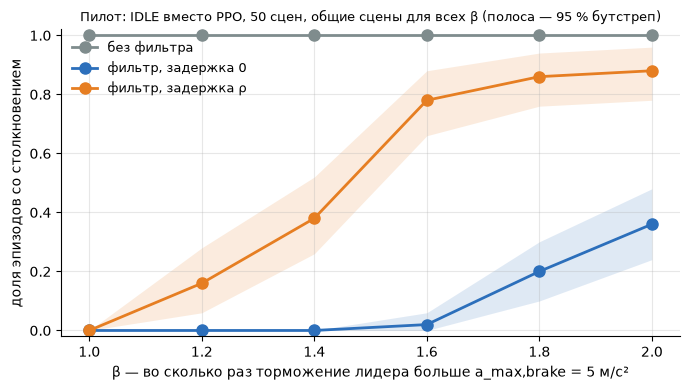

In [6]:
# доля столкновений с 95 % бутстреп-интервалом по сценам (одна «политика» — IDLE)
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(7, 4))
colors = {(False, 0.0): '#7f8c8d', (True, 0.0): '#2c6fbb', (True, 0.5): '#e67e22'}
for key, name in NAMES.items():
    sub = grid[(grid.shield == key[0]) & (grid.reaction_delay == key[1])]
    mat = sub.pivot(index='seed', columns='beta', values='collision').astype(float)[BETAS].to_numpy()
    boot = mat[rng.integers(0, len(mat), (2000, len(mat)))].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    m = mat.mean(axis=0)
    ax.plot(BETAS, m, 'o-', color=colors[key], linewidth=2, markersize=8, label=name)
    ax.fill_between(BETAS, lo, hi, color=colors[key], alpha=0.15, linewidth=0)
ax.set_xlabel('β — во сколько раз торможение лидера больше a_max,brake = 5 м/с²')
ax.set_ylabel('доля эпизодов со столкновением')
ax.set_ylim(-0.02, 1.02)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=9)
ax.set_title('Пилот: IDLE вместо PPO, 50 сцен, общие сцены для всех β (полоса — 95 % бутстреп)', fontsize=9)
fig.tight_layout()
fig.savefig(FIG / '07_pilot_beta_grid.png', dpi=150)

Это пилот без RL, но он уже показывает форму зависимости. С задержкой 0 столкновения начинаются с β ≈ 1,6–1,8, с задержкой ρ — уже с β = 1,2. Без фильтра IDLE врезается всегда (он не тормозит сам). С PPO картина будет другой: политика сама держит дистанцию, поэтому разница между вариантами станет содержательной.

## 4. Сколько сцен нужно на уровень

Сравнения парные: уровень β и β = 1 на одних и тех же сценах. Разброс парной разности определяется долей **несовпадающих пар** d — сцен, где на одном уровне столкновение есть, а на другом нет. Половина ДИ разности ≈ z·√(d/n).

Поправка Холма: сравнений в основной части 5 уровней (β > 1 против β = 1) × 5 вариантов (RL без фильтра; IDM/MOBIL+RSS и RL+RSS — каждый при двух задержках) = 25. Для объема берем самый строгий шаг Холма (уровень 0,05/25).

In [7]:
M = 25
Z = holm_z(M)
print(f'z для 1 сравнения: {holm_z(1):.2f}; z с поправкой Холма (m = {M}, худший шаг): {Z:.2f}')
disc = []
for (sh, d), name in NAMES.items():
    if not sh:
        continue
    sub = grid[grid.shield & (grid.reaction_delay == d)].pivot(index='seed', columns='beta', values='collision')
    disc.append(pd.Series({b: discordance(sub[b], sub[1.0]) for b in BETAS[1:]}, name=name))
disc = pd.DataFrame(disc)
disc.columns = [f'β = {b:g}' for b in BETAS[1:]]
disc.round(2)  # доля несовпадающих пар с β = 1

z для 1 сравнения: 1.96; z с поправкой Холма (m = 25, худший шаг): 3.09


,β = 1.2,β = 1.4,β = 1.6,β = 1.8,β = 2
"фильтр, задержка 0",0.00,0.00,0.02,0.20,0.36
"фильтр, задержка ρ",0.16,0.38,0.78,0.86,0.88


Два разных требования к объему:
- **«Хуже»** (весь ДИ разности > 0) — легко, когда эффект большой. Наименьший эффект, который при n сценах можно назвать «хуже»: δ_min ≈ z²/(n + z²).
- **«Эквивалентно»** (весь ДИ в пределах ±2 п.п.) — трудно: нужно n ≈ z²·d / 0,02². Достижимо только при малом d, то есть там, где эффекта почти нет.

In [8]:
rows = []
for n in (100, 300, 500, 1000, 2000):
    rows.append({'сцен на уровень': n,
                 'δ_min «хуже», п.п. (без поправки)': round(100 * min_detectable(n), 1),
                 'δ_min «хуже», п.п. (Холм)': round(100 * min_detectable(n, Z), 1),
                 'эквивалентность ±2 п.п. возможна при d ≤, п.п. (Холм)': round(100 * n * 0.02 ** 2 / Z ** 2, 2)})
pd.DataFrame(rows).set_index('сцен на уровень')

,"δ_min «хуже», п.п. (без поправки)","δ_min «хуже», п.п. (Холм)","эквивалентность ±2 п.п. возможна при d ≤, п.п. (Холм)"
сцен на уровень,,,
100,3.7,8.7,0.42
300,1.3,3.1,1.26
500,0.8,1.9,2.09
1000,0.4,0.9,4.19
2000,0.2,0.5,8.38


In [9]:
need = pd.DataFrame({
    f'±{w * 100:g} п.п.': [episodes_needed(d, w, Z) for d in (0.01, 0.02, 0.05, 0.1, 0.2)]
    for w in (0.02, 0.03, 0.05)
}, index=[f'd = {d:g}' for d in (0.01, 0.02, 0.05, 0.1, 0.2)])
need.index.name = 'несовпадающих пар'
need  # сцен на уровень, чтобы половина ДИ (с Холмом) была не шире указанной

,±2 п.п.,±3 п.п.,±5 п.п.
несовпадающих пар,,,
d = 0.01,239,107,39
d = 0.02,478,213,77
d = 0.05,1194,531,191
d = 0.1,2388,1062,382
d = 0.2,4775,2123,764


Вывод для плана: **500 сцен на уровень** — разумный компромисс. При нем:
- «хуже» обнаруживается начиная с разности ≈ 2 п.п. (с поправкой Холма);
- «эквивалентно» в пределах ±2 п.п. можно показать, только если несовпадающих пар не больше ≈ 1,9 %. Там, где d больше, а эффект мал, результат честно будет «неопределенно».

**Оговорка.** Это расчет для одной политики. По замечанию 8 бутстреп двухуровневый: сначала политики (seed обучения), затем сцены. Разброс между политиками PPO до обучения неизвестен; если он большой, сужать ДИ нужно числом политик, а не сцен. Число сцен и политик окончательно уточним по первым обученным политикам.

## 5. Сколько займет оценка

In [10]:
mean_sim = grid.t_end.mean()  # в пилоте часть эпизодов короче 40 с из-за столкновений
rows = []
for k in (3, 5):
    for n in (300, 500, 1000):
        plan = evaluation_plan(n_scenes=n, n_policies=k)
        ep = plan['эпизодов всего']
        rows.append({'политик на тип (seed обучения)': k, 'сцен на уровень': n,
                     'эпизодов на сцену и уровень': plan['эпизодов на сцену и уровень'],
                     'эпизодов всего': ep,
                     'часов (все эпизоды по 40 с)': round(ep * 40 / THROUGHPUT / 3600, 1),
                     f'часов (средняя длина как в пилоте, {mean_sim:.0f} с)': round(ep * mean_sim / THROUGHPUT / 3600, 1)})
pd.DataFrame(rows).set_index(['политик на тип (seed обучения)', 'сцен на уровень'])

эпизодов на сцену и уровень  \
политик на тип (seed обучения) сцен на уровень                                
3                              300                                       20   
                               500                                       20   
                               1000                                      20   
5                              300                                       32   
                               500                                       32   
                               1000                                      32   

                                                эпизодов всего  \
политик на тип (seed обучения) сцен на уровень                   
3                              300                       60000   
                               500                      100000   
                               1000                     200000   
5                              300                       96000   
                               500                      160000   
                               1000                     320000   

                                                часов (все эпизоды по 40 с)  \
политик на тип (seed обучения) сцен на уровень                                
3                              300                                     25.5   
                               500                                     42.6   
                               1000                                    85.1   
5                              300                                     40.9   
                               500                                     68.1   
                               1000                                   136.2   

                                                часов (средняя длина как в пилоте, 25 с)  
политик на тип (seed обучения) сцен на уровень                                            
3                              300                                                  15.9  
                               500                                                  26.5  
                               1000                                                 52.9  
5                              300                                                  25.4  
                               500                                                  42.4  
                               1000                                                 84.7

Что входит: 6 уровней β + 4 уровня γ; на каждую сцену и уровень — 2 типа политик PPO × k seed обучения, каждая с фильтром и без (схема 2×2), плюс IDM/MOBIL+RSS без RL; варианты с фильтром — при двух задержках. Дополнительный эксперимент 2 (сочетания β и γ) и контрфактические прогоны сюда не входят: их делаем на меньшем числе сцен (например, 100).

Вариант «5 политик × 500 сцен» — по двум замерам скорости (26 и 35 с симуляции за 1 с счета) от 1,5 до 3 суток счета на этом компьютере, в зависимости от его загрузки. Его можно разбить на ночные прогоны по уровням: результаты по уровням независимы.

## 6. Сколько займет обучение PPO

In [11]:
from rssrl.volume import ppo_steps_per_second
speed = {n: ppo_steps_per_second(n) for n in (1, 8)}
print({f'{k} сред': f'{v:.1f} шагов/с' for k, v in speed.items()})

{'1 сред': '9.4 шагов/с', '8 сред': '24.1 шагов/с'}


In [12]:
rows = []
for budget in (2e4, 1e5, 2e5):
    per_policy_h = budget / speed[8] / 3600
    rows.append({'шагов обучения на политику': f'{budget:.0e}',
                 'часов на 1 политику': round(per_policy_h, 1),
                 'часов на 2 типа × 3 seed': round(6 * per_policy_h, 1),
                 'часов на 2 типа × 5 seed': round(10 * per_policy_h, 1)})
pd.DataFrame(rows).set_index('шагов обучения на политику')

,часов на 1 политику,часов на 2 типа × 3 seed,часов на 2 типа × 5 seed
шагов обучения на политику,,,
2e+04,0.2,1.4,2.3
1e+05,1.2,6.9,11.5
2e+05,2.3,13.8,23.0


Шаг обучения — одно решение политики (1 с симуляции, 15 шагов физики). Замер сделан на обычной highway-v0 с нашим фоном: стоимость шага определяет highway-env, а фильтр ее почти не меняет (раздел 2). Бюджет шагов выберем по кривой обучения первой политики; для highway-env обычно хватает 10⁴–10⁵ шагов.

## Выводы этапа 7

1. Полный эпизод (40 с) — около 4 с на одном ядре и 1,2–1,5 с при параллельном счете на этом компьютере (зависит от загрузки). Время уходит на highway-env, а не на наш код.
2. Пилот по сетке β (IDLE, 50 сцен) показывает четкую зависимость: с задержкой 0 столкновения с β ≈ 1,6–1,8, с задержкой ρ — с β = 1,2.
3. Предлагаемый объем: 500 общих сцен на уровень. С поправкой Холма это позволяет назвать «хуже» разность от ≈ 2 п.п.; «эквивалентно ±2 п.п.» — только при малой доле несовпадающих пар.
4. Оценка «5 политик × 500 сцен» — 1,5–3 суток счета, обучение 10 политик по 10⁵ шагов — 7–12 часов (24–39 шагов/с на 8 средах). Оба числа уточним после первой обученной политики.
5. Неизвестное до обучения: разброс между политиками PPO (seed обучения). От него зависит, сколько политик нужно для двухуровневого бутстрепа.